In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

iq_path = Path(
    r"D:\workspace\preparation\dinov3_11\data\2FSK\2FSK_0001.cf32"
)
fs = 1_000_000

assert iq_path.stat().st_size % 8 == 0, "Invalid IQ file size"

# Little-endian complex64: float32 I followed by float32 Q.
iq = np.fromfile(iq_path, dtype="<c8")

assert iq.size == 2_000_000, "Unexpected sample count"
assert np.isfinite(iq).all(), "IQ contains NaN or Inf"

print("Complex samples:", iq.size)
print("Duration (s):", iq.size / fs)
print("Mean power:", float(np.mean(np.abs(iq) ** 2)))

Complex samples: 2000000
Duration (s): 2.0
Mean power: 0.0006147491512820125


In [2]:
nfft = 512
hop = 256

# Periodic Hann window.
window = np.hanning(nfft + 1)[:-1]

# One row per complete frame.
frames = np.lib.stride_tricks.sliding_window_view(
    iq, nfft
)[::hop]

spectrum = np.fft.fft(frames * window, axis=1)

# Double-sided PSD for complex IQ.
psd = np.abs(spectrum) ** 2 / (fs * np.sum(window ** 2))

# Put negative frequencies before positive frequencies.
psd = np.fft.fftshift(psd, axes=1).T
frequencies = np.fft.fftshift(
    np.fft.fftfreq(nfft, d=1.0 / fs)
)
times = (np.arange(frames.shape[0]) * hop + nfft / 2) / fs

keep = (frequencies >= -250_000) & (frequencies < 250_000)
psd_band = psd[keep]
frequency_band = frequencies[keep]

db = 10 * np.log10(
    np.maximum(psd_band, np.finfo(np.float64).tiny)
)

print("STFT frames:", frames.shape[0])
print("PSD shape:", psd_band.shape)

STFT frames: 7811
PSD shape: (256, 7811)


Saved: D:\workspace\preparation\dinov3_11\output\diagnostics\2FSK_0001_stft.png


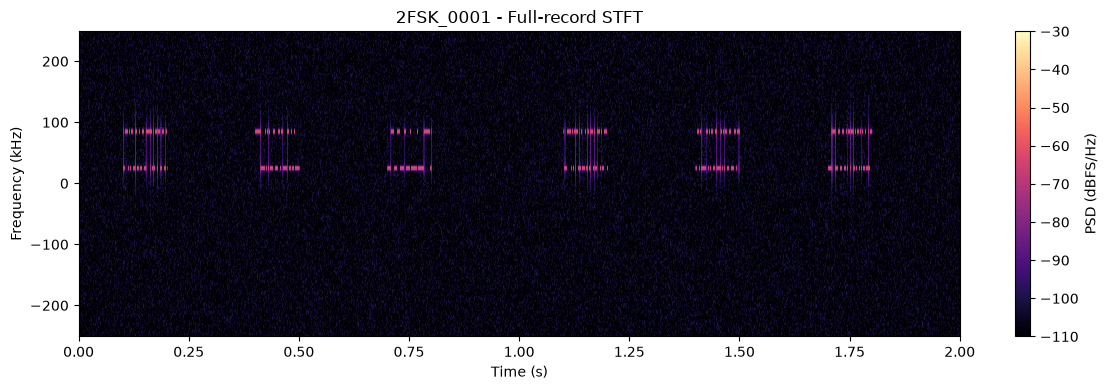

In [3]:
out_dir = Path(
    r"D:\workspace\preparation\dinov3_11\output\diagnostics"
)
out_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 4))

mesh = ax.pcolormesh(
    times,
    frequency_band / 1000,
    db,
    shading="auto",
    cmap="magma",
    vmin=-110,
    vmax=-30,
    rasterized=True,
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Frequency (kHz)")
ax.set_title(f"{iq_path.stem} - Full-record STFT")
ax.set_xlim(0, iq.size / fs)

fig.colorbar(mesh, ax=ax, label="PSD (dBFS/Hz)")
fig.tight_layout()

png_path = out_dir / f"{iq_path.stem}_stft.png"
fig.savefig(png_path, dpi=160)

np.savez_compressed(
    out_dir / f"{iq_path.stem}_stft.npz",
    psd=psd_band,
    frequencies_hz=frequency_band,
    times_seconds=times,
    fs_hz=fs,
    nfft=nfft,
    hop=hop,
    source_path=str(iq_path),
)

print("Saved:", png_path)
plt.show()


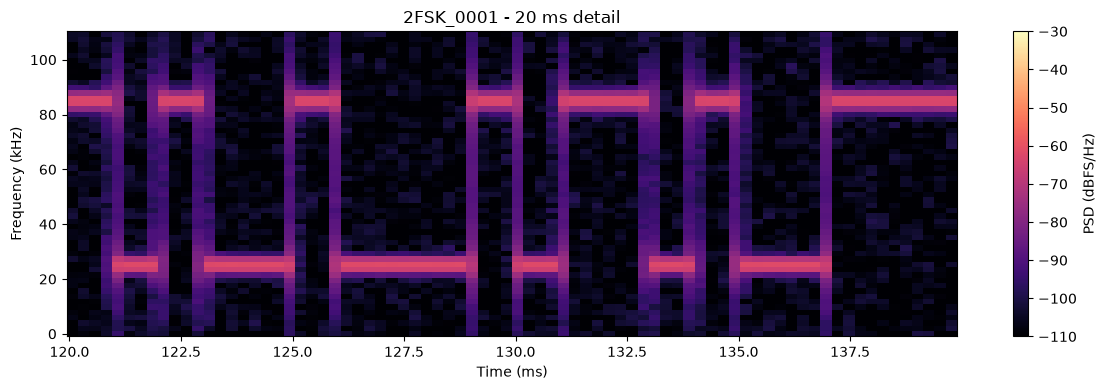

In [4]:
time_mask = (times >= 0.12) & (times <= 0.14)
frequency_mask = (
    (frequency_band >= 0)
    & (frequency_band <= 110_000)
)

fig, ax = plt.subplots(figsize=(12, 4))

mesh = ax.pcolormesh(
    times[time_mask] * 1000,
    frequency_band[frequency_mask] / 1000,
    db[np.ix_(frequency_mask, time_mask)],
    shading="auto",
    cmap="magma",
    vmin=-110,
    vmax=-30,
)

ax.set_xlabel("Time (ms)")
ax.set_ylabel("Frequency (kHz)")
ax.set_title(f"{iq_path.stem} - 20 ms detail")
fig.colorbar(mesh, ax=ax, label="PSD (dBFS/Hz)")
fig.tight_layout()
fig.savefig(
    out_dir / f"{iq_path.stem}_zoom.png",
    dpi=160,
)
plt.show()

In [5]:
# 从整个时频矩阵中抽样，估计背景噪声 PSD
noise_stride = max(
    1, int(np.ceil(psd_band.shape[1] / 256))
)
tiny = np.finfo(np.float64).tiny

noise_psd = max(
    float(np.median(psd_band[:, ::noise_stride])) / np.log(2),
    tiny,
)

# 相邻三个频率格在线性 PSD 上求平均
three_bin_psd = (
    psd_band[:-2]
    + psd_band[1:-1]
    + psd_band[2:]
) / 3.0

# 每个时间帧，寻找最强的局部频谱能量
peak_psd = three_bin_psd.max(axis=0)

# 局部谱峰相对于背景噪声的强度
score_db = 10 * np.log10(
    np.maximum(peak_psd, tiny) / noise_psd
)

threshold_db = 10.0
active = score_db >= threshold_db

print(
    "Estimated noise PSD (dBFS/Hz):",
    10 * np.log10(noise_psd),
)
print("Detection threshold (dB):", threshold_db)

Estimated noise PSD (dBFS/Hz): -106.79198610509243
Detection threshold (dB): 10.0


In [6]:
minimum_seconds = 0.005    # 保留至少 5 ms 的检测段
merge_gap_seconds = 0.002  # 合并不超过 2 ms 的间隙

minimum_samples = int(np.ceil(minimum_seconds * fs))
merge_gap_samples = int(np.floor(merge_gap_seconds * fs))

events = []

for frame_index in np.flatnonzero(active):
    start_sample = int(frame_index * hop)
    stop_sample = min(start_sample + nfft, iq.size)

    if (
        events
        and start_sample - events[-1]["stop_sample"]
        <= merge_gap_samples
    ):
        events[-1]["stop_sample"] = stop_sample
    else:
        events.append({
            "start_sample": start_sample,
            "stop_sample": stop_sample,
        })

# 去除持续时间过短的候选段
events = [
    event for event in events
    if event["stop_sample"] - event["start_sample"]
    >= minimum_samples
]

print("Detected events:", len(events))

for number, event in enumerate(events, start=1):
    start_seconds = event["start_sample"] / fs
    stop_seconds = event["stop_sample"] / fs

    print(
        f"{number:02d}: "
        f"start={start_seconds:.6f} s, "
        f"stop={stop_seconds:.6f} s, "
        f"duration={stop_seconds - start_seconds:.6f} s"
    )

Detected events: 6
01: start=0.099840 s, stop=0.202240 s, duration=0.102400 s
02: start=0.399872 s, stop=0.502016 s, duration=0.102144 s
03: start=0.699904 s, stop=0.802048 s, duration=0.102144 s
04: start=1.099776 s, stop=1.202176 s, duration=0.102400 s
05: start=1.399808 s, stop=1.502208 s, duration=0.102400 s
06: start=1.699840 s, stop=1.802240 s, duration=0.102400 s


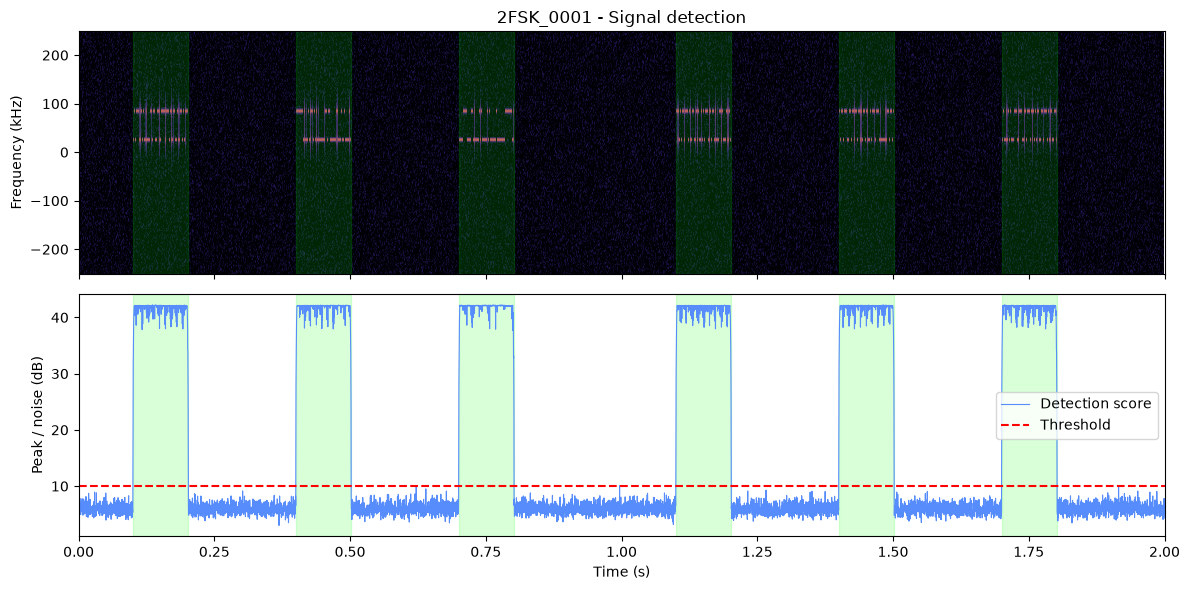

In [7]:
fig, axes = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True
)

mesh = axes[0].pcolormesh(
    times,
    frequency_band / 1000,
    db,
    shading="auto",
    cmap="magma",
    vmin=-110,
    vmax=-30,
    rasterized=True,
)

axes[0].set_ylabel("Frequency (kHz)")
axes[0].set_title(f"{iq_path.stem} - Signal detection")

axes[1].plot(
    times, score_db,
    linewidth=0.8,
    label="Detection score",
)
axes[1].axhline(
    threshold_db,
    color="red",
    linestyle="--",
    label="Threshold",
)

for event in events:
    start_seconds = event["start_sample"] / fs
    stop_seconds = event["stop_sample"] / fs

    for ax in axes:
        ax.axvspan(
            start_seconds,
            stop_seconds,
            color="lime",
            alpha=0.15,
        )

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Peak / noise (dB)")
axes[1].set_xlim(0, iq.size / fs)
axes[1].legend()

fig.tight_layout()
fig.savefig(
    out_dir / f"{iq_path.stem}_detection.png",
    dpi=160,
)
plt.show()

In [8]:
from PIL import Image

tap_count = 129
cutoff_hz = 225_000.0
filter_delay = (tap_count - 1) // 2

tap_positions = np.arange(tap_count) - filter_delay

taps = (
    (2 * cutoff_hz / fs)
    * np.sinc((2 * cutoff_hz / fs) * tap_positions)
    * np.kaiser(tap_count, 8.6)
)

taps /= taps.sum()

In [9]:
if not events:
    raise ValueError("No detected events")

event = events[0]

frame_starts = np.arange(psd_band.shape[1]) * hop
selected = (
    (frame_starts >= event["start_sample"])
    & (frame_starts + nfft <= event["stop_sample"])
    & active
)

weights = np.maximum(
    psd_band[:, selected] - 4.0 * noise_psd,
    0.0,
).sum(axis=1)

if weights.sum() <= 0:
    raise ValueError("Insufficient signal energy")

center_est_hz = float(
    np.dot(frequency_band, weights) / weights.sum()
)

print("Measured energy center (Hz):", center_est_hz)

Measured energy center (Hz): 59751.204528980044


In [10]:
slice_samples = 65536

event_length = (
    event["stop_sample"] - event["start_sample"]
)

if event_length < slice_samples:
    raise ValueError("Event is shorter than one full window")

slice_start = (
    event["start_sample"]
    + (event_length - slice_samples) // 2
)
slice_stop = slice_start + slice_samples

# 129 点对称低通 FIR
tap_count = 129
filter_delay = (tap_count - 1) // 2
cutoff_hz = 225_000.0

tap_positions = np.arange(tap_count) - filter_delay
taps = (
    (2 * cutoff_hz / fs)
    * np.sinc((2 * cutoff_hz / fs) * tap_positions)
    * np.kaiser(tap_count, 8.6)
)
taps /= taps.sum()

# 使用窗口前后真实的相邻 IQ，补偿滤波延迟
context_start = slice_start - filter_delay
context_stop = slice_stop + filter_delay

if context_start < 0 or context_stop > iq.size:
    raise ValueError("Insufficient neighboring IQ for FIR")

context = np.asarray(
    iq[context_start:context_stop],
    dtype=np.complex128,
)
sample_positions = np.arange(context_start, context_stop)

# 将测得的中心频率移到 0 Hz
shifted = context * np.exp(
    -2j * np.pi * center_est_hz * sample_positions / fs
)

iq_slice = np.convolve(shifted, taps, mode="valid")

print("Window samples:", iq_slice.size)
print("Window start (s):", slice_start / fs)
print("Window stop (s):", slice_stop / fs)

Window samples: 65536
Window start (s): 0.118272
Window stop (s): 0.183808


In [11]:
slice_window = np.hanning(nfft + 1)[:-1]

slice_frames = np.lib.stride_tricks.sliding_window_view(
    iq_slice, nfft
)[::hop]

slice_fft = np.fft.fft(slice_frames * slice_window, axis=1)

slice_psd = (
    np.abs(slice_fft) ** 2
    / (fs * np.sum(slice_window ** 2))
)
slice_psd = np.fft.fftshift(slice_psd, axes=1).T

slice_frequencies = np.fft.fftshift(
    np.fft.fftfreq(nfft, d=1.0 / fs)
)

slice_keep = (
    (slice_frequencies >= -250_000)
    & (slice_frequencies < 250_000)
)

slice_psd_band = slice_psd[slice_keep]
slice_freq_hz = slice_frequencies[slice_keep]
slice_times = (
    np.arange(slice_frames.shape[0]) * hop + nfft / 2
) / fs

peak_index = slice_psd_band.mean(axis=1).argmax()

print("Window PSD shape:", slice_psd_band.shape)
print("Aligned peak frequency (Hz):", slice_freq_hz[peak_index])

Window PSD shape: (256, 255)
Aligned peak frequency (Hz): 25390.625


Image shape: (256, 256, 3)
Image saved: D:\workspace\preparation\dinov3_11\output\model_inputs\2FSK\2FSK_0001_event01_window01.png


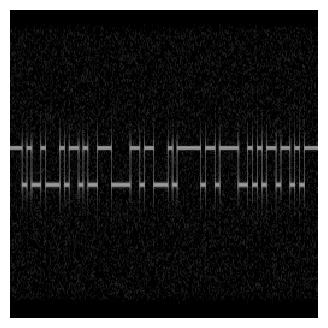

In [12]:
from PIL import Image

low_db = -110.0
high_db = -30.0

slice_db = 10 * np.log10(
    np.maximum(slice_psd_band, np.finfo(np.float64).tiny)
)

gray = np.rint(
    np.clip(
        (slice_db - low_db) / (high_db - low_db),
        0.0,
        1.0,
    ) * 255
).astype(np.uint8)

# 高频放在上方
gray = gray[::-1, :]

# 复制最后一个时间列，适配成正方形
square = np.concatenate(
    (gray, gray[:, -1:]),
    axis=1,
)

# 同一灰度复制到 R、G、B 三个通道
rgb = np.repeat(square[:, :, None], 3, axis=2)

model_dir = (
    Path(r"D:\workspace\preparation\dinov3_11\output\model_inputs")
    / iq_path.parent.name
)
model_dir.mkdir(parents=True, exist_ok=True)

stem = f"{iq_path.stem}_event01_window01"
model_path = model_dir / f"{stem}.png"
Image.fromarray(rgb).save(model_path)

print("Image shape:", rgb.shape)
print("Image saved:", model_path)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(rgb, interpolation="nearest")
ax.axis("off")
plt.show()

In [13]:
matrix_path = out_dir / f"{stem}.npz"

np.savez_compressed(
    matrix_path,
    iq=iq_slice.astype(np.complex64),
    psd=slice_psd_band.astype(np.float32),
    frequencies_hz=slice_freq_hz,
    times_seconds=slice_times,
    source_path=str(iq_path),
    start_sample=slice_start,
    stop_sample=slice_stop,
    center_shift_hz=center_est_hz,
    fs_hz=fs,
    nfft=nfft,
    hop=hop,
    filter_taps=taps,
    filter_delay_samples=filter_delay,
    gray_db_range=np.array([low_db, high_db]),
    image_adaptation="copy_last_time_column",
)

print("Matrix saved:", matrix_path)

Matrix saved: D:\workspace\preparation\dinov3_11\output\diagnostics\2FSK_0001_event01_window01.npz


In [14]:
def export_one_event(event_info, event_number, label):
    # 测量当前检测段的能量中心
    starts = np.arange(psd_band.shape[1]) * hop
    selected = (
        (starts >= event_info["start_sample"])
        & (starts + nfft <= event_info["stop_sample"])
        & active
    )

    weights = np.maximum(
        psd_band[:, selected] - 4.0 * noise_psd,
        0.0,
    ).sum(axis=1)

    if weights.sum() <= 0:
        raise ValueError(f"Event {event_number}: insufficient energy")

    center = float(
        np.dot(frequency_band, weights) / weights.sum()
    )

    # 从当前检测段中间取 65536 点
    length = 65536
    event_length = (
        event_info["stop_sample"] - event_info["start_sample"]
    )
    if event_length < length:
        raise ValueError(f"Event {event_number}: window too short")

    start = int(
        event_info["start_sample"] + (event_length - length) // 2
    )
    stop = start + length

    # 混频和 FIR，保留原始采样位置
    delay = (len(taps) - 1) // 2
    context_start = start - delay
    context_stop = stop + delay

    if context_start < 0 or context_stop > iq.size:
        raise ValueError(f"Event {event_number}: insufficient context")

    context = np.asarray(
        iq[context_start:context_stop],
        dtype=np.complex128,
    )
    positions = np.arange(context_start, context_stop)
    shifted = context * np.exp(
        -2j * np.pi * center * positions / fs
    )
    values = np.convolve(shifted, taps, mode="valid")

    # 固定窗口 STFT
    hann = np.hanning(nfft + 1)[:-1]
    frames = np.lib.stride_tricks.sliding_window_view(
        values, nfft
    )[::hop]

    transformed = np.fft.fft(frames * hann, axis=1)
    psd = np.abs(transformed) ** 2 / (fs * np.sum(hann ** 2))
    psd = np.fft.fftshift(psd, axes=1).T

    frequencies = np.fft.fftshift(
        np.fft.fftfreq(nfft, d=1.0 / fs)
    )
    band = (
        (frequencies >= -250_000)
        & (frequencies < 250_000)
    )
    psd_cut = psd[band]
    times_local = (
        np.arange(frames.shape[0]) * hop + nfft / 2
    ) / fs

    if psd_cut.shape != (256, 255):
        raise ValueError(f"Unexpected PSD shape: {psd_cut.shape}")

    # 固定灰度范围，转换为三通道图片
    db_values = 10 * np.log10(
        np.maximum(psd_cut, np.finfo(np.float64).tiny)
    )
    gray = np.rint(
        np.clip((db_values + 110.0) / 80.0, 0.0, 1.0) * 255
    ).astype(np.uint8)

    gray = gray[::-1, :]
    square = np.concatenate((gray, gray[:, -1:]), axis=1)
    image_rgb = np.repeat(square[:, :, None], 3, axis=2)

    # 保存图片及数值数据
    image_dir = Path(
        r"D:\workspace\preparation\dinov3_11"
        r"\output\model_inputs"
    ) / label
    image_dir.mkdir(parents=True, exist_ok=True)

    name = f"{iq_path.stem}_event{event_number:02d}_window01"
    image_path = image_dir / f"{name}.png"
    numeric_path = out_dir / f"{name}.npz"

    Image.fromarray(image_rgb).save(image_path)

    np.savez_compressed(
        numeric_path,
        iq=values.astype(np.complex64),
        psd=psd_cut.astype(np.float32),
        frequencies_hz=frequencies[band],
        times_seconds=times_local,
        source_path=str(iq_path),
        start_sample=start,
        stop_sample=stop,
        context_start_sample=context_start,
        context_stop_sample=context_stop,
        center_shift_hz=center,
        fs_hz=fs,
        nfft=nfft,
        hop=hop,
        filter_taps=taps,
        filter_delay_samples=delay,
        gray_db_range=np.array([-110.0, -30.0]),
        image_adaptation="copy_last_time_column",
    )

    return {
        "window_id": name,
        "event_number": int(event_number),
        "event_start_sample": int(event_info["start_sample"]),
        "event_stop_sample": int(event_info["stop_sample"]),
        "start_sample": start,
        "stop_sample": stop,
        "center_shift_hz": center,
        "image_path": str(image_path),
        "matrix_path": str(numeric_path),
    }, image_rgb

In [15]:
import json
import hashlib

class_name = iq_path.parent.name
entries = []
previews = []

for number, detected_event in enumerate(events, start=1):
    entry, preview = export_one_event(
        detected_event,
        number,
        class_name,
    )
    entries.append(entry)
    previews.append(preview)

    print(
        f"Event {number:02d}: "
        f"center={entry['center_shift_hz']:.2f} Hz, "
        f"samples={entry['stop_sample'] - entry['start_sample']}"
    )

manifest = {
    "source_group_id": f"{class_name}:{iq_path.stem}",
    "source_path": str(iq_path),
    "source_iq_sha256": hashlib.sha256(iq.tobytes()).hexdigest(),
    "source_format": "cf32_le",
    "sample_rate_hz": float(fs),
    "source_samples": int(iq.size),
    "class_label": class_name,
    "label_source": "GNU Radio signal-generation settings",
    "window_policy": "one centered full window per event",
    "detector": {
        "threshold_db": float(threshold_db),
        "noise_psd": float(noise_psd),
        "minimum_seconds": float(minimum_seconds),
        "merge_gap_seconds": float(merge_gap_seconds),
    },
    "processing": {
        "nfft": int(nfft),
        "hop": int(hop),
        "window": "periodic Hann",
        "frequency_band_hz": [-250000, 250000],
        "gray_db_range": [-110, -30],
        "frequency_order": "high frequency at top",
        "observed_time_columns": 255,
        "image_adaptation": "copy last time column",
        "image_shape": [256, 256, 3],
        "dc_calibration": "not applied; source DC set to zero",
    },
    "windows": entries,
}

manifest_path = out_dir / f"{iq_path.stem}_windows.json"
with manifest_path.open("w", encoding="utf-8") as file:
    json.dump(manifest, file, ensure_ascii=False, indent=2)

print("Exported images:", len(entries))
print("Manifest saved:", manifest_path)

Event 01: center=59751.20 Hz, samples=65536
Event 02: center=49500.75 Hz, samples=65536
Event 03: center=45333.42 Hz, samples=65536
Event 04: center=59282.58 Hz, samples=65536
Event 05: center=56568.94 Hz, samples=65536
Event 06: center=57768.48 Hz, samples=65536
Exported images: 6
Manifest saved: D:\workspace\preparation\dinov3_11\output\diagnostics\2FSK_0001_windows.json


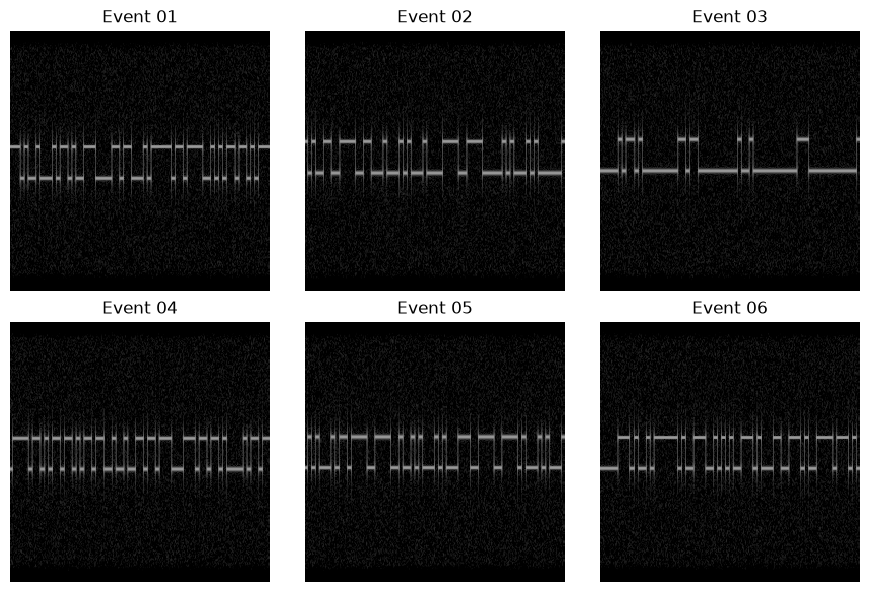

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for ax in axes.flat:
    ax.axis("off")

for ax, preview, entry in zip(
    axes.flat, previews, entries
):
    ax.imshow(preview, interpolation="nearest")
    ax.set_title(f"Event {entry['event_number']:02d}")

fig.tight_layout()
plt.show()